# Tag store products with every applicable label

Which storefront tags, such as *portable*, *kitchen* or *eco friendly*, apply to each newly listed product?
Tags are not mutually exclusive: a laptop is *electronics*, *computing* and *portable*, and some products are also *premium* or *eco friendly*. This is multilabel classification, which scores every tag independently and can predict any number of them per product.

**Kumo Engine · Local CPU notebook · Synthetic data**

For a single category per product, see the [multiclass category example](local_kumo_engine_synthetic_product_category.ipynb).
Run it on Linux with a CPU and writable local storage, as described in [Linux machine deployment](https://docs.nvidia.com/sdgm/kumo-engine/get-started-with-kumo-engine/installation/linux-machine-deployment).
Runtime depends on CPU resources and the selected training settings.

## Install Kumo Engine

The text extra provides the word embeddings used to encode product titles.

In [ ]:
%pip install -q "kumo-engine[text]"

## Configure the example

Use the defaults to generate a small store catalog and a full `FAST` training run.
Each run creates its own directory under `OUTPUT_PARENT` for data, scratch files, the model and saved predictions.
A local SSD is recommended for faster ingestion.
`SMOKE_MODE = True` limits training to a quick check that the workflow runs.

Outputs default to `kumo_example_runs` under the current directory.
Set `KUMO_LOCAL_SSD` to use another writable local directory.


In [1]:
import os

SEED = 7
N_BRANDS = 120
N_PRODUCTS = 3000
N_CUSTOMERS = 2000
N_PURCHASES = 30000
N_NEW_PRODUCTS = 200
N_NEW_PURCHASES = 2000
THRESHOLD = 0.5  # Minimum score for a tag to be predicted.
OUTPUT_PARENT = os.environ.get("KUMO_LOCAL_SSD", "kumo_example_runs")
SMOKE_MODE = False
CLEANUP = False

Import the tools and create this run's data and scratch directories.
Deterministic PyTorch operations let the reloaded model reproduce the saved scores on CPU.

In [2]:
from pathlib import Path
from importlib.metadata import version
import os
import shutil
import tempfile

import torch
torch.use_deterministic_algorithms(True)

import numpy as np
import pandas as pd
from IPython.display import display
import kumo.engine as kumo
from kumoapi.model_plan import RunMode
from kumoapi.typing import Dtype, Stype

output_parent = Path(OUTPUT_PARENT).expanduser().resolve()
output_parent.mkdir(parents=True, exist_ok=True)
run_dir = Path(tempfile.mkdtemp(prefix="product-tags-", dir=output_parent))
data_dir = run_dir / "data"
data_dir.mkdir()
kumo.configure(scratch_dir=str(run_dir / "scratch"))
print(f"Engine {version('kumo-engine')} | results: {run_dir}")

/tmp/kumo-notebook-runtime/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Engine 1.0.0.dev0+b840a3ed | results: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_tags/20261109T184029Z/kumo_example_runs/product-tags-3wgnfr3s


## Generate synthetic example data

Run the next cell to create an invented store catalog with brands, products, customers and purchases.
You can skim the generation code; the Kumo workflow starts at **Build the graph**.

| Table | Contents |
| --- | --- |
| `brands` | Invented brands with a price tier and an eco certification flag |
| `products` | Products with a brand, a title, a price and a shipping weight |
| `customers` | Invented customers with a shopper segment |
| `purchases` | Purchase lines linking a customer to a product |

Each product belongs to one of 14 categories and carries several storefront tags.
Brands specialize in a few categories and customers buy mostly from a few categories they prefer, so related products share brands and buyers.
Those specialties and preferences are hidden and never supplied as features.
Titles name the product type only part of the time, so the model also has to use brands, prices and purchases.
The same cell also reserves new products and their observed purchases for the later scoring batch.

In [3]:
rng = np.random.default_rng(SEED)
# Category: (storefront tags, product nouns, price range in dollars, weight range in kg)
CATALOG = {
    "laptops": (["electronics", "computing", "portable"], ["laptop", "notebook pc", "chromebook"], (300, 1800), (1.0, 2.8)),
    "smartphones": (["electronics", "mobile", "portable"], ["smartphone", "phone", "5g handset"], (120, 1300), (0.15, 0.25)),
    "headphones": (["electronics", "audio", "portable"], ["headphones", "earbuds", "headset"], (15, 400), (0.05, 0.4)),
    "televisions": (["electronics", "video", "home"], ["tv", "television", "smart display"], (180, 2500), (6.0, 30.0)),
    "printers": (["electronics", "computing", "office"], ["printer", "scanner", "all-in-one"], (60, 600), (4.0, 15.0)),
    "office supplies": (["office"], ["stapler", "binder", "pen set", "desk organizer"], (2, 45), (0.05, 1.5)),
    "kitchen appliances": (["home", "kitchen", "electronics"], ["blender", "toaster", "kettle", "stand mixer"], (20, 450), (1.0, 8.0)),
    "cookware": (["home", "kitchen"], ["skillet", "saucepan", "stock pot", "bakeware set"], (12, 250), (0.5, 6.0)),
    "toys": (["toys", "kids"], ["puzzle", "building blocks", "board game", "plush toy"], (6, 90), (0.1, 2.0)),
    "baby care": (["kids", "personal care"], ["diapers", "baby wipes", "bottle set", "baby lotion"], (4, 70), (0.2, 4.0)),
    "personal care": (["personal care"], ["shampoo", "toothbrush", "razor", "body lotion"], (3, 60), (0.1, 1.0)),
    "outdoor gear": (["outdoor", "sports", "portable"], ["tent", "hiking backpack", "camp lantern", "cooler"], (15, 450), (0.3, 9.0)),
    "fitness": (["sports", "health"], ["dumbbell set", "yoga mat", "resistance bands", "jump rope"], (8, 350), (0.2, 25.0)),
    "groceries": (["grocery"], ["coffee beans", "cereal", "pasta", "snack mix"], (2, 30), (0.2, 2.0)),
}
CATEGORIES = list(CATALOG)
ADJECTIVES = ["classic", "compact", "deluxe", "everyday", "pro", "smart", "ultra", "value"]
GENERIC_NOUNS = ["bundle", "essentials kit", "multipack", "set", "starter pack"]
SEGMENTS = ["family", "student", "professional", "outdoors", "home cook", "budget"]

brand_tier = rng.choice(["value", "standard", "premium"], N_BRANDS, p=[0.4, 0.4, 0.2])
brands = pd.DataFrame({
    "brand_id": [f"synthetic-brand-{i:03d}" for i in range(N_BRANDS)],
    "tier": brand_tier,
    "eco_certified": rng.random(N_BRANDS) < 0.25,
})
# Hidden: each brand makes products in two to four categories.
brand_categories = [rng.choice(len(CATEGORIES), rng.integers(2, 5), replace=False) for _ in range(N_BRANDS)]
tier_position = {"value": (0.0, 0.5), "standard": (0.25, 0.8), "premium": (0.6, 1.0)}

customers = pd.DataFrame({
    "customer_id": [f"synthetic-customer-{i:05d}" for i in range(N_CUSTOMERS)],
    "segment": rng.choice(SEGMENTS, N_CUSTOMERS),
})
# Hidden: each customer buys mostly from three preferred categories.
customer_categories = np.array([rng.choice(len(CATEGORIES), 3, replace=False) for _ in range(N_CUSTOMERS)])


def make_products(n, first_id):
    """Invent products; only the category and tags columns reveal their labels."""
    brand = rng.integers(0, N_BRANDS, n)
    category = np.array([rng.choice(brand_categories[b]) for b in brand])
    rows = []
    for b, c in zip(brand, category):
        tags, nouns, (low, high), (light, heavy) = CATALOG[CATEGORIES[c]]
        position = rng.uniform(*tier_position[brand_tier[b]])
        price = round(float(np.exp(np.log(low) + position * (np.log(high) - np.log(low)) + rng.normal(0, 0.4))), 2)
        noun = rng.choice(nouns) if rng.random() < 0.35 else rng.choice(GENERIC_NOUNS)
        product_tags = set(tags)
        if position > 0.8:
            product_tags.add("premium")
        if brands.eco_certified[b]:
            product_tags.add("eco friendly")
        rows.append({"brand_id": brands.brand_id[b],
                     "title": f"{rng.choice(ADJECTIVES)} {noun}",
                     "price": price,
                     "weight_kg": round(float(rng.uniform(light, heavy) * rng.lognormal(0, 0.4)), 2),
                     "category": CATEGORIES[c],
                     "tags": "|".join(sorted(product_tags))})
    frame = pd.DataFrame(rows)
    frame.insert(0, "product_id", [f"synthetic-product-{i:05d}" for i in range(first_id, first_id + n)])
    return frame


def make_purchases(product_frame, n, first_id):
    """Customers buy mostly from their preferred categories, sometimes from any category."""
    by_category = product_frame.groupby("category").product_id.agg(list)
    buyer = rng.integers(0, N_CUSTOMERS, n)
    product_ids = []
    for b in buyer:
        category = CATEGORIES[rng.choice(customer_categories[b])] if rng.random() < 0.8 else rng.choice(CATEGORIES)
        candidates = by_category.get(category) or product_frame.product_id.tolist()
        product_ids.append(rng.choice(candidates))
    return pd.DataFrame({
        "purchase_id": [f"synthetic-purchase-{i:06d}" for i in range(first_id, first_id + n)],
        "customer_id": customers.customer_id.to_numpy()[buyer],
        "product_id": product_ids,
        "quantity": rng.integers(1, 4, n),
    })


catalog = make_products(N_PRODUCTS, first_id=0)
purchases = make_purchases(catalog, N_PURCHASES, first_id=0)
display(pd.DataFrame({"rows": {"brands": len(brands), "products": len(catalog),
                               "customers": len(customers), "purchases": len(purchases)}}))
catalog.head()

# Reserve the new batch now; append it only after fitting.
new_products = make_products(N_NEW_PRODUCTS, first_id=N_PRODUCTS)
new_purchases = make_purchases(new_products, N_NEW_PURCHASES, first_id=N_PURCHASES)
simulated_labels = new_products[["product_id", "tags"]]

,rows
brands,120
products,3000
customers,2000
purchases,30000


Keep the columns the model may see, with `tags` as the label; `category` belongs to the multiclass example.
Each product's tags are one `|`-delimited string.

In [4]:
LABELLED_COLUMNS = ["product_id", "brand_id", "title", "price", "weight_kg", "tags"]
labelled_products = catalog[LABELLED_COLUMNS]
ALL_TAGS = sorted({tag for tags in catalog.tags for tag in tags.split("|")})
print(len(ALL_TAGS), "tags; average per product:", round(catalog.tags.str.count("[|]").add(1).mean(), 2))
catalog.tags.str.split("|").explode().value_counts().to_frame("products")

18 tags; average per product: 2.63


,products
tags,
electronics,1269
portable,835
eco friendly,744
personal care,565
home,511
kids,483
computing,475
office,473
sports,395


Check that keys are unique and every purchase points to a known customer and product.

In [5]:
assert catalog.product_id.is_unique and brands.brand_id.is_unique and customers.customer_id.is_unique
assert purchases.purchase_id.is_unique
assert catalog.brand_id.isin(brands.brand_id).all()
assert purchases.customer_id.isin(customers.customer_id).all()
assert purchases.product_id.isin(catalog.product_id).all()
assert labelled_products.tags.notna().all()
print("Keys and relationships are valid.")

Keys and relationships are valid.


## Build the graph

Save the tables as local Parquet and connect them with [Engine tables and graphs](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs).
Titles are encoded as text; `brands` and `purchases` connect each product to related products through shared brands and shared buyers.
`tags` is the prediction target, so the model never uses it as an input feature.
Keep the construction helper for the batch prediction step.

In [6]:
def save_tables(table_dir, product_rows, purchase_rows):
    table_dir.mkdir(exist_ok=True)
    product_rows.to_parquet(table_dir / "products.parquet", index=False)
    purchase_rows.to_parquet(table_dir / "purchases.parquet", index=False)
    brands.to_parquet(table_dir / "brands.parquet", index=False)
    customers.to_parquet(table_dir / "customers.parquet", index=False)


def build_graph(table_dir):
    files = kumo.FileConnector(root_dir=str(table_dir))
    products = (kumo.Table.from_source_table(files["products"], primary_key="product_id")
                .with_column("brand_id", stype=Stype.ID)
                .with_column("title", stype=Stype.text)
                .with_column("price", stype=Stype.numerical)
                .with_column("weight_kg", stype=Stype.numerical)
                .with_column("tags", stype=Stype.multicategorical, dtype=Dtype.string,
                             multicategorical_delimiter="|"))
    brand_table = (kumo.Table.from_source_table(files["brands"], primary_key="brand_id")
                   .with_column("tier", stype=Stype.categorical)
                   .with_column("eco_certified", stype=Stype.categorical))
    customer_table = (kumo.Table.from_source_table(files["customers"], primary_key="customer_id")
                      .with_column("segment", stype=Stype.categorical))
    purchase_table = (kumo.Table.from_source_table(files["purchases"], primary_key="purchase_id")
                      .with_column("customer_id", stype=Stype.ID)
                      .with_column("product_id", stype=Stype.ID)
                      .with_column("quantity", stype=Stype.numerical))
    return kumo.Graph(
        tables={"products": products, "brands": brand_table,
                "customers": customer_table, "purchases": purchase_table},
        edges=[kumo.Edge("products", "brand_id", "brands"),
               kumo.Edge("purchases", "customer_id", "customers"),
               kumo.Edge("purchases", "product_id", "products")],
    )


save_tables(data_dir, labelled_products, purchases)
graph = build_graph(data_dir)
graph.validate()
print("Graph validated:", ", ".join(graph.tables))

Graph validated: products, brands, customers, purchases


Inspect the tables and relationships before training with the graph's native [visualization](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs#visualize-table-relationships).
The relationship table lists each foreign key and its destination.


,table,foreign_key,references
0,products,brand_id,brands
1,purchases,customer_id,customers
2,purchases,product_id,products


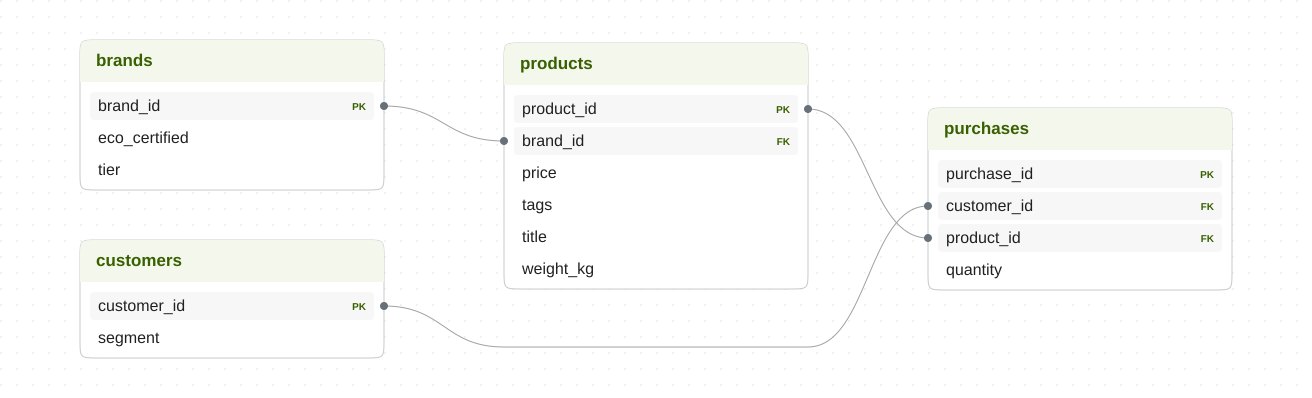

In [7]:
relationships = pd.DataFrame(
    [(edge.src_table, edge.fkey, edge.dst_table) for edge in graph.edges],
    columns=["table", "foreign_key", "references"],
)
display(relationships)

display(graph.visualize(show_cols=True))


## Define the prediction question

Predict each product's tags: `tags` is a multicategorical column, so the query must say `CLASSIFY`, and `TOP` is set to the number of tags so every tag receives a score.
A static query fits because the label is a fixed product attribute rather than an outcome in a future time window, so Kumo assigns labelled products to training, validation and test splits at random.
See [Predictive queries](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries) for the syntax.

In [8]:
QUERY = f"PREDICT products.tags CLASSIFY TOP {len(ALL_TAGS)} FOR EACH products.product_id"
query = kumo.PredictiveQuery(graph, QUERY)
query.validate()
assert query.get_task_type() == "multilabel_classification"
print(QUERY)
print("Task:", query.get_task_type())

PREDICT products.tags CLASSIFY TOP 18 FOR EACH products.product_id
Task: multilabel_classification


Materialize a snapshot of the graph and generate the training rows: one per labelled product.

In [9]:
snapshot = graph.snapshot()
training_table = query.generate_training_table(snapshot)
training_rows = pd.read_parquet(training_table.train_table_path)
print("Training rows:", len(training_rows))
training_rows.head()

/tmp/ipykernel_1323353/3933969833.py:1: UserWarning: The kumo.engine scratch directory /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_tags/20261109T184029Z/kumo_example_runs/product-tags-3wgnfr3s/scratch is on Amazon EBS. Graph sampling and training-table generation read it randomly and run much slower there; local NVMe is recommended.
  snapshot = graph.snapshot()


ingest: table started phase="encode" table=products


ingest: table producers complete phase="encode" table=products rows=3000 elapsed_ms=179


ingest: Ingestion stage progress phase=Encode table=products shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=brands


ingest: table producers complete phase="encode" table=brands rows=120 elapsed_ms=6


... (23 outputs left out)

diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 4 node tables, 6 edge relations, 35120 nodes, 126000 edges


Training rows: 3000


,ENTITY1,TIMESTAMP,TARGET1
0,synthetic-product-00000,1970-01-01,computing|electronics|office
1,synthetic-product-00001,1970-01-01,electronics|home|video
2,synthetic-product-00002,1970-01-01,eco friendly|electronics|home|kitchen
3,synthetic-product-00003,1970-01-01,eco friendly|home|kitchen
4,synthetic-product-00004,1970-01-01,health|sports


## Train the model

Fit the suggested `FAST` plan and publish the model bundle to the run directory for the reload step.
Smoke mode caps epochs and steps only to check that the workflow runs.
See [Training](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training) for the available settings.

In [10]:
plan = query.suggest_model_plan(snapshot, run_mode=RunMode.FAST)
if SMOKE_MODE:
    plan.optimization.max_epochs = 1
    plan.optimization.max_steps_per_epoch = 20

trainer = kumo.Trainer(plan, accelerator="cpu")
model_store = kumo.FileConnector(root_dir=str(run_dir))
fit_result = trainer.fit(training_table, snapshot=snapshot,
                         export_config=kumo.ModelOutputConfig(model_store, path="model"))

Text column 'products.title' will not be encoded by default: its values are too short or have too few known words. To encode it anyway, set its encoder to TextEmbedding().


[I 2026-11-09 18:40:53,566] A new study created in memory with name: no-name-06ded0fb-da76-434b-8eca-3ca585acee64


GPU available: False, used: False


TPU available: False, using: 0 TPU cores



  | Name           | Type                          | Params | Mode  | FLOPs
---------------------------------------------------------------------------------
0 | target_encoder | MultiCategoricalTargetEncoder | 0      | train | 0    
1 | metric_store   | MetricStore                   | 0      | train | 0    
2 | loss           | BinaryCrossEntropyLoss        | 0      | train | 0    
3 | calibrator     | PlatScaling                   | 2      | train | 0    
4 | encoder        | HeteroTensorFrameEncoder      | 6.7 K  | train | 0    
5 | model          | HeteroGNN                     | 2.1 M  | train | 0    
6 | head           | NodePredHead                  | 4.6 K  | train | 0    
---------------------------------------------------------------------------------
2.1 M     Trainable params
0         Non-trainable params
2.1 M     Total params
8.471     Total estimated model params size (MB)
184       Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (214 outputs left out)

Testing DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Testing DataLoader 0: 100%|██████████| 2/2 [00:02<00:00,  0.97it/s]

Testing DataLoader 0: 100%|██████████| 2/2 [00:04<00:00,  0.47it/s]


────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss           0.17425669729709625
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


## Evaluate the model

Read the validation and test metrics from the fit.
Average precision (`ap`) and AUROC summarize how well each tag's scores separate products that carry it from those that do not.
These metrics come from synthetic data and are **demonstration only**.

In [11]:
split_metrics = {name: value for name, value in fit_result.metrics.items()
                 if name.startswith(("val_", "test_"))}
display(pd.Series(split_metrics, name="value").to_frame())

,value
val_loss,0.155761
val_ap_macro,0.797839
val_ap_micro,0.865991
val_auprc_macro,0.792647
val_auprc_micro,0.865916
...,...
test_auroc_per_label_grocery,0.928151
test_auroc_per_label_toys,0.934497
test_auroc_per_label_outdoor,0.914851
test_auroc_per_label_health,0.987188


## Batch predictions

### Inspect the reserved scoring data

New products arrive without a tag set.
The setup cell reserved these products and their observed purchases from existing customers using the same generators. Check their row counts and disjoint IDs before adding them to the graph.
Their simulated labels are kept aside for the comparison below and never enter the graph.

In [12]:
assert set(new_products.product_id).isdisjoint(catalog.product_id)
assert set(new_purchases.purchase_id).isdisjoint(purchases.purchase_id)
print(f"New products: {len(new_products)}; their purchases: {len(new_purchases)}")

New products: 200; their purchases: 2000


Add the new products with an empty `tags` and their purchases to a separate copy of the tables, then refresh the graph snapshot.

In [13]:
scoring_dir = run_dir / "data_with_new_products"
unlabelled_new = new_products[LABELLED_COLUMNS].assign(tags=None)
save_tables(scoring_dir,
            pd.concat([labelled_products, unlabelled_new], ignore_index=True),
            pd.concat([purchases, new_purchases], ignore_index=True))
scoring_graph = build_graph(scoring_dir)
scoring_graph.validate()
scoring_snapshot = scoring_graph.snapshot()
print("Products in the refreshed graph:", len(labelled_products) + len(unlabelled_new))

ingest: table started phase="encode" table=products


ingest: table producers complete phase="encode" table=products rows=3200 elapsed_ms=81


ingest: Ingestion stage progress phase=Encode table=products shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=brands


ingest: table producers complete phase="encode" table=brands rows=120 elapsed_ms=2


ingest: Ingestion stage progress phase=Encode table=brands shard=None progress_pct=100 current=1 total=1


... (21 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 4 node tables, 6 edge relations, 37320 nodes, 134400 edges


Products in the refreshed graph: 3200


A static query scores the products whose target is empty, so the [batch prediction population](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/making-predictions) is exactly the new products.

In [14]:
scoring_query = kumo.PredictiveQuery(scoring_graph, QUERY)
population = scoring_query.generate_prediction_table(
    scoring_snapshot, plan=trainer.training_table_generation_plan)
scoring_rows = pd.read_parquet(population.table_path)
assert set(scoring_rows.ENTITY1) == set(new_products.product_id)
print("Products to score:", len(scoring_rows))

Products to score: 200


Score the new products with an explicit threshold.
Each tag's `SCORE` is an independent probability, so a product's scores do not sum to one, and `PREDICTED` marks every tag above `THRESHOLD`.

In [15]:
predictions = trainer.predict(population, snapshot=scoring_snapshot,
                              num_classes_to_return=len(ALL_TAGS),
                              binary_classification_threshold=THRESHOLD).frame
assert set(predictions.ENTITY) == set(new_products.product_id)
assert predictions.groupby("ENTITY").size().eq(len(ALL_TAGS)).all()
assert not predictions.duplicated(["ENTITY", "CLASS"]).any()
assert predictions.SCORE.between(0, 1).all()

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_tags/20261109T184029Z/kumo_example_runs/product-tags-3wgnfr3s/scratch/trainers/1b4c3e2fa1174c3a95629e63b4c29704/runs/1b4c3e2fa1174c3a95629e63b4c29704-predict-e3e21eade9fe4d6ba10af14108fd9893/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_tags/20261109T184029Z/kumo_example_runs/product-tags-3wgnfr3s/scratch/trainers/1b4c3e2fa1174c3a95629e63b4c29704/runs/1b4c3e2fa1174c3a95629e63b4c29704-predict-e3e21eade9fe4d6ba10af14108fd9893/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 35.43it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 28.23it/s]

### Save the predictions

`ENTITY` is the product, `CLASS` a tag, `SCORE` its probability and `PREDICTED` whether it clears the threshold; each product has one row per tag.
Preview each product's predicted tags next to its title, and save every row so the threshold can be changed later without scoring again.

In [16]:
predicted_tags = (predictions[predictions.PREDICTED].groupby("ENTITY").CLASS
                  .agg(lambda tags: sorted(tags)).rename("predicted_tags"))
preview = new_products[["product_id", "title", "price"]].merge(
    predicted_tags, left_on="product_id", right_index=True, how="left")
preview["predicted_tags"] = preview.predicted_tags.map(lambda tags: tags if isinstance(tags, list) else [])
display(preview.head(10))

prediction_path = run_dir / "tag_predictions.parquet"
predictions.rename(columns={"ENTITY": "product_id", "CLASS": "tag", "SCORE": "probability"}
                   ).to_parquet(prediction_path, index=False)
print(f"Saved {len(predictions)} rows for {predictions.ENTITY.nunique()} products to {prediction_path}")

,product_id,title,price,predicted_tags
0,synthetic-product-03000,everyday desk organizer,7.51,[]
1,synthetic-product-03001,ultra shampoo,23.44,[personal care]
2,synthetic-product-03002,deluxe essentials kit,6.64,[personal care]
3,synthetic-product-03003,deluxe coffee beans,8.09,"[eco friendly, personal care]"
4,synthetic-product-03004,deluxe essentials kit,274.83,"[electronics, mobile, portable]"
5,synthetic-product-03005,compact set,7.23,[kids]
6,synthetic-product-03006,pro set,11.14,"[kids, personal care]"
7,synthetic-product-03007,compact all-in-one,444.25,"[computing, eco friendly, electronics, office,..."
8,synthetic-product-03008,smart multipack,464.87,"[electronics, mobile, portable]"
9,synthetic-product-03009,classic jump rope,164.41,"[computing, electronics, health, sports]"


Saved 3600 rows for 200 products to /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_tags/20261109T184029Z/kumo_example_runs/product-tags-3wgnfr3s/tag_predictions.parquet


## Compare with the simulated tags

Check the predicted tag sets against the tags the simulation assigned to the new products.
Micro F1 pools every product-tag decision, macro F1 averages over tags so rarer tags count equally, and exact match counts products whose whole tag set is right.
The baseline gives every product the most common complete tag set in the catalog.
These synthetic-data metrics are **demonstration only**.

In [17]:
from sklearn.metrics import f1_score
from sklearn.preprocessing import MultiLabelBinarizer

binarizer = MultiLabelBinarizer(classes=ALL_TAGS)
truth = simulated_labels.set_index("product_id").tags.str.split("|")
actual = binarizer.fit_transform(truth)
predicted = binarizer.transform(preview.set_index("product_id").predicted_tags.loc[truth.index])
most_common_set = labelled_products.tags.mode()[0].split("|")
baseline = binarizer.transform([most_common_set] * len(truth))


def quality(predicted_matrix):
    return {"Micro F1": f1_score(actual, predicted_matrix, average="micro", zero_division=0),
            "Macro F1": f1_score(actual, predicted_matrix, average="macro", zero_division=0),
            "Exact match": (actual == predicted_matrix).all(axis=1).mean()}


display(pd.DataFrame({"Engine model": quality(predicted), "Most-common-set baseline": quality(baseline)}).round(3))

,Engine model,Most-common-set baseline
Micro F1,0.718,0.295
Macro F1,0.625,0.070
Exact match,0.410,0.065


Per-tag F1 shows which tags the model assigns reliably and which need more examples or a different threshold.

In [18]:
pd.DataFrame({"new products": actual.sum(axis=0),
              "F1": f1_score(actual, predicted, average=None, zero_division=0)},
             index=ALL_TAGS).sort_values("new products", ascending=False).round(3)

,new products,F1
electronics,94,0.897
portable,63,0.786
eco friendly,50,1.000
computing,42,0.800
home,37,0.615
office,32,0.635
personal care,31,0.545
kitchen,28,0.409
premium,26,0.565
sports,25,0.419


## Reload and score again

Restore the published bundle with [Publish and retrieve models](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/publish-and-retrieve-models) and score the same new products without fitting again.
The reloaded model must return the same candidates, with scores within 0.0001 of the saved predictions.

In [19]:
reloaded = kumo.Trainer.load_from_connector(model_store, path="model", accelerator="cpu")
rescored = reloaded.predict(population, snapshot=scoring_snapshot, num_classes_to_return=len(ALL_TAGS), binary_classification_threshold=THRESHOLD).frame
key = ["ENTITY", "CLASS"]
original = predictions.sort_values(key).reset_index(drop=True)
restored = rescored.sort_values(key).reset_index(drop=True)
pd.testing.assert_frame_equal(original[key], restored[key])
max_difference = (original.SCORE - restored.SCORE).abs().max()
print("Reloaded scores:", len(restored), "| maximum absolute difference:", max_difference)
pd.testing.assert_series_equal(original.SCORE, restored.SCORE, rtol=0, atol=1e-4)

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_tags/20261109T184029Z/kumo_example_runs/product-tags-3wgnfr3s/scratch/trainers/ad74372716a14cd4b362c013a3f8452d/runs/ad74372716a14cd4b362c013a3f8452d-predict-dda3f0166ded4973a7c7b8dac34ed64e/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_tags/20261109T184029Z/kumo_example_runs/product-tags-3wgnfr3s/scratch/trainers/ad74372716a14cd4b362c013a3f8452d/runs/ad74372716a14cd4b362c013a3f8452d-predict-dda3f0166ded4973a7c7b8dac34ed64e/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 36.66it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 30.80it/s]

Reloaded scores: 3600 | maximum absolute difference: 0.0


## Keep or remove this run's files

`CLEANUP = False` keeps the generated tables, model bundle and predictions in the run directory.
Set `CLEANUP = True` to remove only the directory created by this notebook.

In [20]:
if CLEANUP:
    shutil.rmtree(run_dir)
print("Removed this run's files." if CLEANUP else f"Results retained in {run_dir}.")

Results retained in /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_tags/20261109T184029Z/kumo_example_runs/product-tags-3wgnfr3s.
